# **Naive Bayes**

In this notebook we will look at **Naive Bayes**.

Do some imports.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.naive_bayes import GaussianNB
from sklearn.naive_bayes import BernoulliNB

from sklearn.preprocessing import StandardScaler

from matplotlib.colors import ListedColormap
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# **Let's start by trying Gaussian Naive Bayes on the Iris dataset**

First, load the data.

In [2]:
from sklearn.datasets import load_iris
iris = load_iris()

Take the data with features 2 and 3.

In [3]:
X = iris.data[:, (2, 3)]
y = iris.target_names[iris.target] == 'versicolor'

scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Create a model.

In [4]:
nb = GaussianNB()
nb.fit(X, y)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[100., 50.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.67,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[bool](2,)","[False, True]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 2)","[[-0.14,-0.08], [ 0.29, 0.17]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 2)","[[1.4 ,1.45], [0.07,0.07]]"


Plot it.

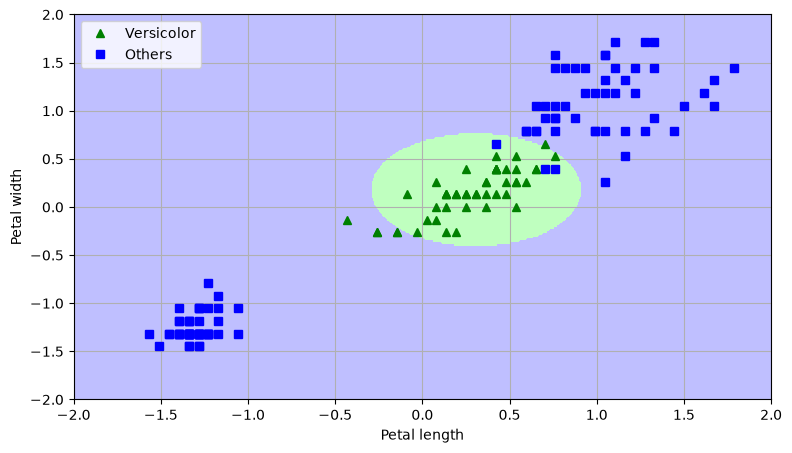

In [5]:
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

zz = nb.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 1, 0], X[y == 1, 1], "g^", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "bs", label="Others")

custom_cmap = ListedColormap(["#bfbfff", "#bfffbf"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

Evaluate it.

In [6]:
yHat = cross_val_predict(nb, X, y, cv=10)

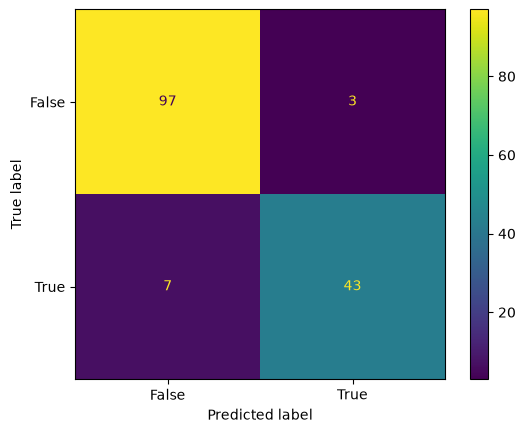

In [7]:
ConfusionMatrixDisplay.from_predictions(y, yHat)

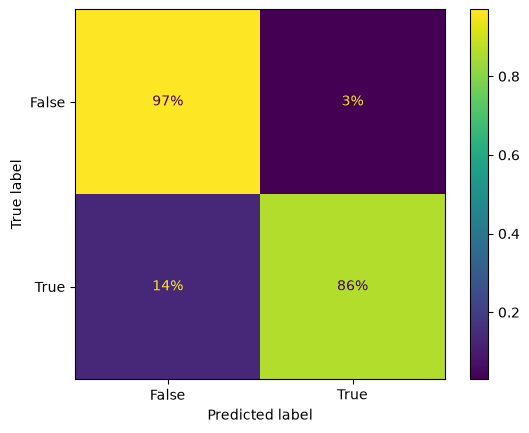

In [8]:
ConfusionMatrixDisplay.from_predictions(y, yHat, normalize="true", values_format=".0%")

# **Let's try all three classes**

We will do the same processing but with all three classes that the dataset offers.

In [9]:
X = iris.data[:, (2, 3)]
y = iris.target

scaler = StandardScaler().fit(X)
X = scaler.transform(X)

Create a model.

In [10]:
nb = GaussianNB()
nb.fit(X, y)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[50.,50.,50.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 2)","[[-1.3 ,-1.25], [ 0.29, 0.17], [ 1.02, 1.09]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 2)","[[0.01,0.02], [0.07,0.07], [0.1 ,0.13]]"


Plot it.

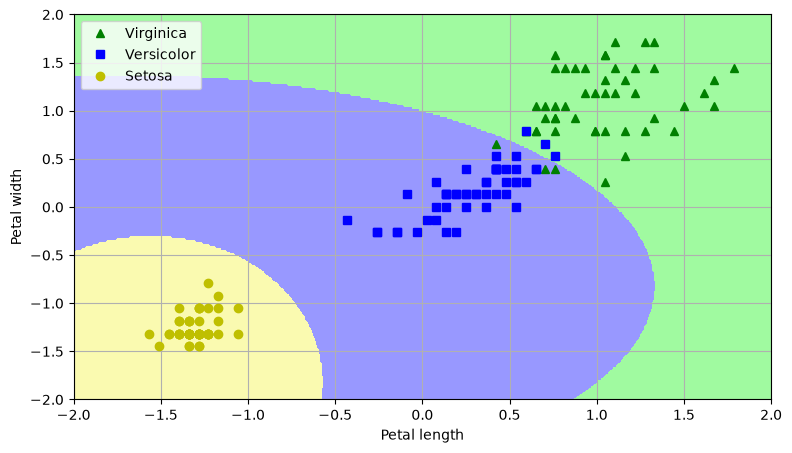

In [11]:
x0, x1 = np.meshgrid(np.linspace(-2, 2, 500).reshape(-1, 1), np.linspace(-2, 2, 200).reshape(-1, 1))
X_new = np.c_[x0.ravel(), x1.ravel()]

zz =  nb.predict(X_new).reshape(x0.shape)

plt.figure(figsize=(9, 5))
plt.plot(X[y == 2, 0], X[y == 2, 1], "g^", label="Virginica")
plt.plot(X[y == 1, 0], X[y == 1, 1], "bs", label="Versicolor")
plt.plot(X[y == 0, 0], X[y == 0, 1], "yo", label="Setosa")

custom_cmap = ListedColormap(["#fafab0", "#9898ff", "#a0faa0"])
plt.contourf(x0, x1, zz, cmap=custom_cmap)
plt.xlabel("Petal length")
plt.ylabel("Petal width")
plt.legend(loc="upper left")
plt.grid()
plt.show()

Evaluate it.

In [12]:
yHat = cross_val_predict(nb, X, y, cv=10)

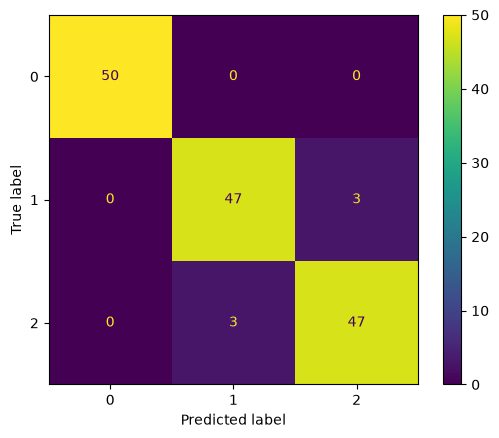

In [13]:
ConfusionMatrixDisplay.from_predictions(y, yHat)

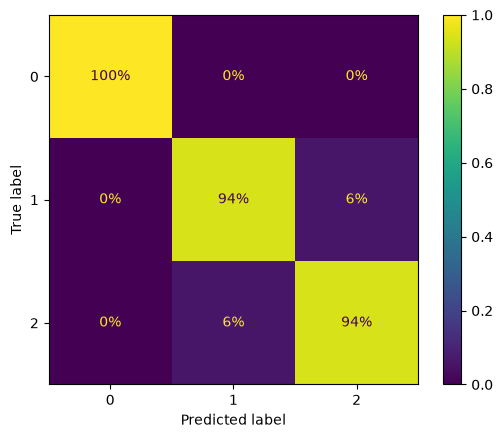

In [14]:
ConfusionMatrixDisplay.from_predictions(y, yHat, normalize="true", values_format=".0%")

# **Now let's try Bernoulli Naive Bayes on a simplified email spam dataset**

Our dataset consists of 13 emails. Each is encoded as a vector with its elements representing presence or absence of a particular word in the text of the email. The words are as follows: `hi` `dear` `buy` `sell` `question` `project` `pill` `click`.

In [15]:
data = np.array([
    [1, 0, 0, 0, 1, 0, 0, 0, 0],
    [0, 1, 1, 0, 0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0, 0, 0, 1, 1],
    [1, 0, 0, 1, 1, 0, 0, 0, 1],
    [1, 0, 0, 0, 0, 1, 0, 0, 0],
    [0, 1, 0, 0, 1, 1, 0, 0, 0],
    [0, 1, 0, 0, 0, 1, 0, 1, 0],
    [1, 1, 1, 1, 1, 0, 1, 1, 1],
    [1, 0, 0, 1, 1, 0, 0, 0, 1],
    [0, 1, 0, 0, 0, 1, 0, 0, 0],
    [0, 1, 0, 1, 0, 0, 1, 1, 1],
    [1, 0, 1, 0, 1, 1, 0, 0, 0],
    [1, 0, 1, 0, 0, 1, 0, 1, 1]])
X = data[:, 0:8]
y = data[:, 8]

Create a model.

In [16]:
nb = BernoulliNB()
nb.fit(X, y)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[6.,7.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.77,-0.62]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 8)","[[3.,3.,1.,...,5.,0.,1.], [4.,3.,4.,...,1.,3.,5.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 8)","[[-0.69,-0.69,-1.39,...,-0.29,-2.08,-1.39], [-0.59,-0.81,-0.59,...,-1.5 ,-0.81,-0.41]]"


Use the model for classifying a new email with the following contents: ~~`hi`~~ `dear` ~~`buy`~~ `sell` `question` `project` ~~`pill`~~ ~~`click`~~.

In [17]:
xq = np.array([[0, 1, 0, 1, 1, 1, 0, 0]])
print(nb.predict_proba(xq))
print("Spam" if nb.predict(xq) else "Not spam")

[[0.82201377 0.17798623]]
Not spam


In [18]:
xq = np.array([[0, 1, 1, 0, 0, 0, 1, 1]])
print(nb.predict_proba(xq))
print("Spam" if nb.predict(xq) else "Not spam")

[[0.03762656 0.96237344]]
Spam


# **Let's try implementing Bernoulli Naive Bayes from scratch**

In [19]:
py = [np.mean(y == 0), np.mean(y == 1)]  # Class priors
alpha = 1  # Laplace smoothing parameter

# Guaranteeing binary data
X[X != 0] = 1

# Number of features
m = X.shape[1]

# Log probabilities for each class
log_probs = []

# Loop over the two classes (0 and 1)
for c in range(0, 2):
    pxy = np.empty(m)  # For storing the conditional probabilities for each feature

    Ny = np.sum(y == c)  # Count training examples with class being c

    # Loop over the m features
    for j in range(0, m):
        # Count how many times the feature has the same value as the query
        Nj = np.sum(X[y == c, j] == xq[0, j])
        # Compute probability with applied Laplace smoothing
        pxy[j] = (Nj + alpha) / (Ny + alpha * 2)

    # Compute log of posterior (sum of logs to avoid underflow)
    log_p = np.log(py[c]) + np.sum(np.log(pxy))
    log_probs.append(log_p)

# Convert log probabilities to probabilities (exponentiate and normalize)
probs = np.exp(log_probs)  # Exponentiate the log probabilities
probs /= np.sum(probs)  # Normalize to sum to 1 (softmax)

# Output probabilities for each class
print(f'Class 0 probability: {probs[0]}')
print(f'Class 1 probability: {probs[1]}')

# Predicted class is the one with the highest probability
predicted_class = np.argmax(probs)  # Get the index of the maximum probability
print(f'Predicted class: {predicted_class}')
print("Spam" if predicted_class else "Not spam")

Class 0 probability: 0.0376265580787599
Class 1 probability: 0.9623734419212401
Predicted class: 1
Spam


<br>
<br>
<br>
<br>
<br>
<br>

---
<small>*Notebook by Gints Jēkabsons*</small>